<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/02_Zero_Day_Attack_Detection/HybridVQC_UnseenRansomware_Le2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid PCA + VQC for unseen-ransomware detection: Le et al. (2025) step by step

This notebook re-implements, runs and checks the experiment of

> Huu Phu Le, Phuc Hao Do, Vo Hoang Long Nguyen and Nang Hung Van Nguyen,
> "A Non-Monotonic Relationship: An Empirical Analysis of Hybrid Quantum Classifiers for Unseen Ransomware Detection",
> arXiv:2509.07924 [quant-ph], 9 September 2025. https://arxiv.org/abs/2509.07924
> Authors' code: https://github.com/ailabteam/qml-ransomware-project

**What the notebook does.** It downloads the "Ransomware Combined Structural Feature Dataset" (2,675 Windows executables, 1,567
static PE-header / structural features, ransomware families that never appear in the training set), trains the paper's three
classical baselines (Logistic Regression, Random Forest, XGBoost) on all 1,567 features, and then trains the paper's hybrid
model: StandardScaler -> PCA to 4, 8 or 12 components -> a Variational Quantum Classifier (`ZZFeatureMap` + `RealAmplitudes`,
COBYLA) with one qubit per component. It reports accuracy, precision, recall, F1 and AUC on the unseen-family test set, redraws
the paper's Table 1, Table 2 and Figures 2 and 3, and gives a verdict for every claim.

On top of the paper it adds four cheap diagnostics that test the paper's *explanations* for the weak VQC and for the
"non-monotonic" trend: (1) classical models trained on the same 4/8/12 PCA inputs (is it an information bottleneck?), (2) several
random initial points per qubit count (is the 4 -> 8 -> 12 pattern reproducible or a single-run accident?), (3) the same VQC with
angles rescaled to [0, pi] (is the encoding the problem?), and (4) the variance of the cost-function gradient at random
parameters (is there evidence of a barren plateau?).

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned
Qiskit versions; if Colab asks to restart the session, restart and run all again. No GPU and no IBM Quantum account are needed.

**Runtime.** `FAST_MODE = True` (400 training files, shorter COBYLA budgets) takes roughly 10 minutes on a CPU; `FAST_MODE = False`
follows the paper's budgets (all 2,157 training files, 100 / 80 / 80 COBYLA evaluations) and takes about an hour, almost all of it
the 12-qubit run. Exact figures for the committed run are printed at the end of the notebook.

**What you get at the end.** Side-by-side tables of the paper's numbers and ours, a verdict per claim, and a critical reading of
what the experiment can and cannot say about quantum machine learning for zero-day ransomware.

## The paper in one page

**Problem.** Detect *unseen* ("zero-day") ransomware: a classifier is trained on some ransomware families and tested on families it
has never seen, so that memorising family-specific signatures does not help.

**Decision.** Binary classification of one executable, from pre-extracted static features: ransomware (positive class, `RG = 1`)
versus benign software (`RG = 0`). Recall on ransomware is the paper's priority metric.

**Data.** Moreira, Moreira and Sales Jr., "Ransomware Combined Structural Feature Dataset" (Mendeley Data, doi 10.17632/yzhcvn7sj5.2):
2,675 samples = 2,157 training + 518 test, `D = 1567` static features; 25 ransomware families in training and 15 *different*
families in test. All features are standardised with `StandardScaler` fitted on the training set only.

**Classical baselines.** Logistic Regression, Random Forest, XGBoost on all 1,567 features.

**Hybrid model.** PCA (fitted on the training set) to `n in {4, 8, 12}` components -> one qubit per component -> `ZZFeatureMap` ->
`RealAmplitudes` -> measure -> threshold. Trained with COBYLA (100 iterations for 4 qubits, 80 for 8 and 12 qubits), Qiskit 1.4.4,
noise-free simulator, seed 42. Cost: mean squared error, Eq. 8 (the Qiskit `VQC` class actually uses cross-entropy, see below).

**Claims we can test.**

| # | Claim | Where |
|---|---|---|
| C1 | Dataset sizes: 2,157 train, 518 test, 25 / 15 disjoint families, 1,567 features | Sec. 3.1 |
| C2 | Explained variance of 4 / 8 / 12 PCA components: 19.14 / 29.07 / 35.50 % | Table 1 |
| C3 | Classical baselines: LR acc 97.10, rec 97.66, AUC 0.9920; RF 95.95 / 95.84 / 0.9940; XGB 95.75 / 95.06 / 0.9940 | Table 2 |
| C4 | VQC 4 qubits: acc 48.65, prec 78.47, rec 42.60, F1 55.22, AUC 0.5994 | Table 2 |
| C5 | VQC 8 qubits: acc 44.98, prec 74.04, rec 40.00, F1 51.94, AUC 0.4624 | Table 2 |
| C6 | VQC 12 qubits: acc 51.74, prec 73.36, rec 55.06, F1 62.91, AUC 0.5374 | Table 2 |
| C7 | Every VQC is far worse than the classical baselines (best VQC recall 55.06 % vs 97.66 %, a gap above 42 points) | Sec. 4.3 |
| C8 | Recall is non-monotonic in the number of qubits: 4q 42.60 > 8q 40.00 < 12q 55.06 | Fig. 3 |
| C9 | Training dynamics: the 4-qubit cost decreases steadily, the 8-qubit cost is flat from the start, the 12-qubit cost decreases slightly | Sec. 4.4 |
| C10 | Explanation: the weak VQC is caused by an information bottleneck (PCA keeps only 19-36 % of the variance) *and* by barren-plateau trainability problems | Sec. 5 |

C1-C9 are measurements; C10 is an interpretation, which the diagnostics in sections 9-12 put to the test.

## What follows the paper and what had to be chosen

The paper states the dataset, the split principle, the preprocessing, the feature map, the ansatz, the optimiser and the iteration
budgets. It does not state the feature-map repetitions, the ansatz repetitions, the entanglement pattern, the initial point, the
exact train/test file lists, the loss that is really minimised, the baseline hyper-parameters, or the number of shots. The authors'
public repository fills most of these gaps, and we follow it where the paper is silent.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Mendeley Data doi 10.17632/yzhcvn7sj5.2 | Same CSV, downloaded from the authors' GitHub repository (Mendeley itself needs a browser); two mirrors tried |
| Train / test split | 2,157 / 518 files, disjoint families | Authors' code: `ID` ranges 10000-11133 and 20000-21022 (train), 12000-12132 and 22000-22384 (test). We verify the sizes and the family disjointness |
| Preprocessing | StandardScaler fitted on train; PCA to 4 / 8 / 12 | Same; `PCA(n, random_state=42)` fitted on the (standardised) training set |
| Feature map | `ZZFeatureMap` | `zz_feature_map(n, reps=1)`, default full entanglement (authors' code: `reps=1`) |
| Ansatz | `RealAmplitudes` | `real_amplitudes(n, reps=3)` (authors' code: `reps=3`, default entanglement) |
| Angle encoding | PCA outputs fed directly | Same: **no rescaling**, PCA scores of order +-10 are used as rotation angles (the authors do the same). A [0, pi] rescaling is run as an ablation (section 11) |
| Read-out / loss | "Z_0 expectation, MSE" (Eq. 7-8) | Qiskit `VQC` default: bit-string parity `x mod 2` (= the value of qubit 0), one-hot targets, cross-entropy. This is what the authors' code runs, so it is what we run |
| Optimiser | COBYLA, 100 iterations (4q), 80 (8q, 12q) | Same (`maxiter`). The authors' JSON file for 8 qubits says 100; the text says 80. We follow the text |
| Initial point | not given | Authors' code: `np.random.default_rng(seed).random(n_params)` |
| Simulator | "noise-free `AerSampler`", Qiskit 1.4.4 | Exact, shot-free probabilities (what the authors' reference `Sampler` computes). Implemented with a small vectorised NumPy simulator because Qiskit's per-circuit simulation needs more than a day for 12 qubits on a CPU; it is checked against `Statevector` to 1e-12 below. Qiskit 2.5.2 / qiskit-machine-learning 0.9.1 instead of 1.4.4 |
| Classical baselines | LR, RF, XGBoost, "hyper-parameters tuned by cross-validation" | Authors' code uses defaults (`LogisticRegression(max_iter=1000)`, `RandomForest(100)`, `XGBClassifier()`); we do the same. No tuning is visible in their code |
| Metrics | accuracy, precision, recall, F1, AUC; ransomware = positive | Same. AUC from the VQC class-1 probability |
| Number of runs | one (seed 42) | Seed 42 reproduces the paper's single run; extra initial points (seeds 43...) measure how much the result depends on it |

Every such choice is marked `# CHOICE:` in the code.

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and xgboost.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc xgboost sympy
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False         # True: class demo (about 10 min). False: the paper's budgets (about 1 h, mostly the 12-qubit run).

SEED         = 42                  # the paper's global seed
N_QUBITS_LIST = [4, 8, 12]         # = number of PCA components = number of qubits (paper)
FEATURE_MAP_REPS = 1               # CHOICE: authors' code
ANSATZ_REPS      = 3               # CHOICE: authors' code

if FAST_MODE:
    N_TRAIN   = 400                # random subset of the 2,157 training files (stratified by label)
    MAXITER   = {4: 40, 8: 40, 12: 50}   # COBYLA needs at least n_params + 2 = 50 evaluations for 12 qubits
    EXTRA_SEEDS = [43, 44]         # extra random initial points for the 4- and 8-qubit models
    EXTRA_SEEDS_12Q = []           # extra initial points for the 12-qubit model
    ABLATION_QUBITS = [4, 8]       # qubit counts for the [0, pi] encoding ablation
    GRAD_DRAWS, GRAD_SAMPLES = 10, 60
else:
    N_TRAIN   = None               # all 2,157 training files, as in the paper
    MAXITER   = {4: 100, 8: 80, 12: 80}   # paper, Sec. 4.1
    EXTRA_SEEDS = [43, 44, 45, 46]
    EXTRA_SEEDS_12Q = []           # 12 qubits cost about 20-40 min per run on a CPU
    ABLATION_QUBITS = [4, 8]       # 12 qubits would add another 20-40 min
    GRAD_DRAWS, GRAD_SAMPLES = 30, 100

TEST_SIZE_NOTE = "fixed by the dataset (518 files, 16 families incl. benign)"   # no random split: the split is by family
LIVE_PLOT  = True                  # redraw the loss curve every LIVE_EVERY COBYLA evaluations
LIVE_EVERY = 10
IBM_TOKEN  = ""                    # not used: the paper simulates everything noise-free

DATA_DIR   = "data"                # CSV cache (relative to the working directory)
LOCAL_CSV  = ""                    # optional: path of a ransomware_features.csv you uploaded yourself
DATA_URLS  = [
    "https://raw.githubusercontent.com/ailabteam/qml-ransomware-project/HEAD/data/ransomware_features.csv",
    "https://cdn.jsdelivr.net/gh/ailabteam/qml-ransomware-project@main/data/ransomware_features.csv",
    "https://github.com/ailabteam/qml-ransomware-project/raw/HEAD/data/ransomware_features.csv",
]

In [3]:
import os, time, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, qiskit, qiskit_machine_learning, xgboost, scipy
from IPython.display import clear_output
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix)
from xgboost import XGBClassifier
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore", message=".*MAXFUN.*")
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
for m in (np, pd, sklearn, qiskit, qiskit_machine_learning, xgboost, scipy):
    print(f"{m.__name__:28s}{m.__version__}")
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()

numpy                       2.5.4
pandas                      3.0.6
sklearn                     1.9.1
qiskit                      2.5.2
qiskit_machine_learning     0.9.1
xgboost                     3.4.1
scipy                       1.18.1


### 0.1 An exact, vectorised simulator for the VQC (so that 12 qubits are feasible on a CPU)

The Qiskit `VQC` asks its `Sampler` for the outcome probabilities of one circuit *per training file* at *every* COBYLA step.
With the reference sampler one 12-qubit circuit costs about 20 ms, i.e. 2,157 files x 80 steps = more than an hour of pure
simulation per run *per core*, and in practice far more. The cell below is a **drop-in `SamplerV2`** that is mathematically
identical to the reference (exact probabilities, no shot noise, no hardware noise) but evaluates all files at once with NumPy
and caches the feature-map half of the circuit, because the data do not change during training. Two further details:

* `fast_postprocess` replaces the Python loops that turn a probability table into class probabilities by two array sums.
  The class of a bit string is `x mod 2` (the Qiskit `VQC` default parity read-out), i.e. the value of qubit 0.
* For 11 or more qubits the state is stored in single precision (`complex64`); probabilities then differ by about 1e-7.

The next cell defines it and proves, for random inputs, that it reproduces Qiskit's own `Statevector` probabilities.

In [4]:
# CHOICE: speed-up only; the quantum model and the maths are unchanged.
import types, time
import numpy as np
import sympy
from qiskit.primitives import BaseSamplerV2

_SUPPORTED = {"h", "x", "p", "rz", "ry", "rx", "cx"}


class _Meas:
    """Minimal stand-in for a SamplerV2 BitArray holding EXACT probabilities."""
    def __init__(self, probs):
        self.probs = probs                     # (B, 2**n), little-endian basis index
    def get_counts(self, i=None):
        row = self.probs[i]
        return {int(k): float(row[k]) for k in np.flatnonzero(row > 1e-14)}


class _PubResult:
    def __init__(self, probs):
        self.data = types.SimpleNamespace(meas=_Meas(probs))


class _Job:
    def __init__(self, res): self._res = res
    def result(self): return self._res


class ExactBatchedSampler(BaseSamplerV2):
    """Exact (shot-free) SamplerV2 for circuits made of h/x/p/rz/ry/rx/cx gates.

    Simulates all rows of the parameter array at once with numpy.  Gates that only
    depend on the data columns (the feature map) are applied once and cached, because
    during COBYLA training the data never changes - only the weights do.
    """
    def __init__(self, n_data_params, dtype=np.complex128):
        self.n_data = n_data_params; self.dtype = dtype
        self._plan = None; self._plan_key = None
        self._cache_key = None; self._cache_state = None
        self.n_calls = 0

    # ---- compile circuit into a list of (name, qubits, angle_fn, is_data_only)
    def _compile(self, circuit):
        circ = circuit.remove_final_measurements(inplace=False)
        for _ in range(8):
            if all(i.operation.name in _SUPPORTED for i in circ.data): break
            circ = circ.decompose()
        bad = {i.operation.name for i in circ.data} - _SUPPORTED
        if bad: raise ValueError(f"unsupported gates {bad}")
        params = list(circuit.parameters)
        pos = {p: k for k, p in enumerate(params)}
        ops = []
        for ins in circ.data:
            name = ins.operation.name
            qs = [circ.find_bit(q).index for q in ins.qubits]
            fn = None; data_only = True
            if ins.operation.params:
                a = ins.operation.params[0]
                if hasattr(a, "parameters") and len(a.parameters) > 0:
                    ps = list(a.parameters)
                    cols = [pos[p] for p in ps]
                    f = sympy.lambdify([p.sympify() if hasattr(p, "sympify") else sympy.Symbol(p.name) for p in ps],
                                       a.sympify(), "numpy")
                    fn = (lambda f, cols: (lambda V: f(*[V[:, c] for c in cols])))(f, cols)
                    data_only = all(c < self.n_data for c in cols)
                else:
                    val = float(a); fn = (lambda val: (lambda V: np.full(V.shape[0], val)))(val)
            ops.append((name, qs, fn, data_only))
        # data-only PREFIX (ops are applied in order; stop at first weight-dependent op)
        k = 0
        while k < len(ops) and ops[k][3]: k += 1
        return circ.num_qubits, ops, k

    @staticmethod
    def _apply(state, n, name, qs, ang):
        B = state.shape[0]
        def ax(q): return n - q                 # axis of qubit q in (B, 2, ..., 2)
        if name == "cx":
            c, t = ax(qs[0]), ax(qs[1])
            idx = [slice(None)] * (n + 1); idx[c] = 1
            sub = state[tuple(idx)]
            ta = t - 1 if t > c else t
            state[tuple(idx)] = np.flip(sub, axis=ta).copy()
            return state
        a = ax(qs[0])
        s = np.moveaxis(state, a, 1)           # view: (B, 2, ...)
        if name == "x":
            s[:] = np.flip(s, axis=1).copy(); return state
        if name == "h":
            s0 = s[:, 0].copy(); s1 = s[:, 1].copy(); r = 1 / np.sqrt(2)
            s[:, 0] = (s0 + s1) * r; s[:, 1] = (s0 - s1) * r; return state
        bshape = (B,) + (1,) * (n - 1)
        th = ang.reshape(bshape).astype(state.real.dtype)
        if name == "p":
            s[:, 1] *= np.exp(1j * th); return state
        if name == "rz":
            s[:, 0] *= np.exp(-0.5j * th); s[:, 1] *= np.exp(0.5j * th); return state
        c, sn = np.cos(th / 2), np.sin(th / 2)
        s0 = s[:, 0].copy(); s1 = s[:, 1].copy()
        if name == "ry":
            s[:, 0] = c * s0 - sn * s1; s[:, 1] = sn * s0 + c * s1; return state
        if name == "rx":
            s[:, 0] = c * s0 - 1j * sn * s1; s[:, 1] = -1j * sn * s0 + c * s1; return state
        raise ValueError(name)

    def _simulate(self, circuit, V):
        key = id(circuit)
        if self._plan_key != key:
            self._plan = self._compile(circuit); self._plan_key = key; self._cache_key = None
        n, ops, k = self._plan
        B = V.shape[0]
        dkey = (V[:, :self.n_data].tobytes(), B)
        if self._cache_key != dkey:
            st = np.zeros((B,) + (2,) * n, dtype=self.dtype); st.reshape(B, -1)[:, 0] = 1.0
            for name, qs, fn, _ in ops[:k]:
                st = self._apply(st, n, name, qs, fn(V) if fn else None)
            self._cache_key, self._cache_state = dkey, st
        st = self._cache_state.copy()
        for name, qs, fn, _ in ops[k:]:
            st = self._apply(st, n, name, qs, fn(V) if fn else None)
        return (np.abs(st.reshape(B, -1)).astype(np.float64) ** 2)

    def run(self, pubs, *, shots=None):
        self.n_calls += 1
        out = []
        for pub in pubs:
            circuit, values = pub[0], np.asarray(pub[1], dtype=float)
            if values.ndim == 1: values = values[None, :]
            out.append(_PubResult(self._simulate(circuit, values)))
        return _Job(out)


def fast_postprocess(self, num_samples, result):
    """Vectorised replacement for SamplerQNN._postprocess (same maths, no python loops)."""
    probs = result[0].data.meas.probs[:num_samples]
    if not hasattr(self, "_class_of"):
        self._class_of = np.array([int(self._interpret(k)) for k in range(probs.shape[1])])
    out = np.zeros((num_samples,) + tuple(self._output_shape))
    for c in range(self._output_shape[0]):
        out[:, c] = probs[:, self._class_of == c].sum(axis=1)
    return out


def use_fast_postprocess(vqc):
    qnn = vqc.neural_network
    qnn._postprocess = types.MethodType(fast_postprocess, qnn)
    return vqc



In [5]:
# Correctness check against Qiskit's own statevector simulation (random data and random weights).
chk_rng = np.random.default_rng(0)
for n in (3, 4, 6):
    fm_t = zz_feature_map(n, reps=FEATURE_MAP_REPS); an_t = real_amplitudes(n, reps=ANSATZ_REPS)
    smp_t = ExactBatchedSampler(n)
    vqc_t = VQC(feature_map=fm_t, ansatz=an_t, optimizer=COBYLA(maxiter=1), sampler=smp_t)
    circ_t = vqc_t.neural_network._circuit
    V = chk_rng.normal(0, 3, size=(6, n + an_t.num_parameters))
    mine = smp_t._simulate(circ_t, V)
    base = circ_t.remove_final_measurements(inplace=False)
    ref = np.array([Statevector.from_instruction(base.assign_parameters(dict(zip(circ_t.parameters, row)))).probabilities()
                    for row in V])
    print(f"{n} qubits: max |p_fast - p_qiskit| = {np.abs(mine - ref).max():.2e}")
    assert np.allclose(mine, ref, atol=1e-10)
print("Exact simulator agrees with qiskit.quantum_info.Statevector.")

3 qubits: max |p_fast - p_qiskit| = 3.50e-14
4 qubits: max |p_fast - p_qiskit| = 1.10e-14


6 qubits: max |p_fast - p_qiskit| = 8.60e-15
Exact simulator agrees with qiskit.quantum_info.Statevector.


## 1. Data: the Ransomware Combined Structural Feature Dataset

The CSV has one row per executable. Columns: `ID` (encodes dataset origin and split), `filename`, `RG` (the label: 1 =
ransomware, 0 = benign / "goodware"), `family` (0 = benign, 1-40 = ransomware family) and 1,567 numeric static features taken
from the PE header and structure of the file (DOS-header fields, section names, import / API indicators, ...). Nothing in the
file is synthetic: the paper's keyword "synthetic data" in our index refers to the title of a cited VQC paper (ref. 20), not to this
dataset.

The notebook downloads the CSV from the authors' repository (11 MB), caches it in `DATA_DIR`, or uses `LOCAL_CSV` if you set it.

In [6]:
def get_csv():
    if LOCAL_CSV and os.path.exists(LOCAL_CSV):
        return LOCAL_CSV
    path = os.path.join(DATA_DIR, "ransomware_features.csv")
    if os.path.exists(path) and os.path.getsize(path) > 5_000_000:
        return path
    import requests
    last = None
    for url in DATA_URLS:
        try:
            r = requests.get(url, timeout=120)
            r.raise_for_status()
            if len(r.content) < 5_000_000:
                raise ValueError("file too small")
            with open(path, "wb") as f: f.write(r.content)
            print("downloaded", url); return path
        except Exception as e:
            last = e; print("failed:", url, e)
    raise RuntimeError(f"Could not download the dataset ({last}). Upload ransomware_features.csv and set LOCAL_CSV.")

df = pd.read_csv(get_csv())
df.columns = df.columns.str.strip()
print(df.shape)
display(df.iloc[:3, :8])
print(df["RG"].value_counts().rename({0: "benign", 1: "ransomware"}))

(2675, 1571)


,ID,filename,RG,family,e_cblp,e_cp,e_crlc,e_cparhdr
0,10000,2XClient_12.0_build_2193.paf.exe,0,0,0.00162,0.000038,0.0,0.000142
1,10001,7-ZipPortable_21.07.paf.exe,0,0,0.00162,0.000038,0.0,0.000142
2,10002,ARP.EXE,0,0,0.00162,0.000038,0.0,0.000142


RG
ransomware    1408
benign        1267
Name: count, dtype: int64


### 1.1 The family hold-out protocol (claim C1)

The paper's split is by *family*, not by file: the 25 training families and the 15 test families are disjoint. In the CSV the split
is encoded in the `ID` ranges (the authors' code selects them explicitly). We reproduce that selection and check the claim.
Benign files carry `family = 0` in both sets, but they are different files: only the ransomware families are held out.

In [7]:
# CHOICE: ID ranges copied from the authors' code (the paper only describes the split in words).
is_train = ((df.ID >= 10000) & (df.ID <= 11133)) | ((df.ID >= 20000) & (df.ID <= 21022))
is_test  = ((df.ID >= 12000) & (df.ID <= 12132)) | ((df.ID >= 22000) & (df.ID <= 22384))
train_df, test_df = df[is_train].copy(), df[is_test].copy()
FEATURES = [c for c in df.columns if c not in ("ID", "filename", "RG", "family")]
tr_fam = set(train_df.loc[train_df.RG == 1, "family"]); te_fam = set(test_df.loc[test_df.RG == 1, "family"])
c1 = pd.DataFrame({
    "quantity": ["train files", "test files", "features D", "ransomware families in train", "ransomware families in test",
                 "families shared by train and test", "ransomware share train", "ransomware share test"],
    "paper": [2157, 518, 1567, 25, 15, 0, "n/a", "n/a"],
    "notebook": [len(train_df), len(test_df), len(FEATURES), len(tr_fam), len(te_fam), len(tr_fam & te_fam),
                 f"{train_df.RG.mean():.3f}", f"{test_df.RG.mean():.3f}"]})
display(c1)
assert len(train_df) == 2157 and len(test_df) == 518 and len(FEATURES) == 1567 and not (tr_fam & te_fam)

X_tr_raw, y_tr_all = train_df[FEATURES].values.astype(float), train_df["RG"].values
X_te_raw, y_te = test_df[FEATURES].values.astype(float), test_df["RG"].values
print("test set: %d ransomware / %d benign (majority-class accuracy = %.1f %%)"
      % (y_te.sum(), (1 - y_te).sum(), 100 * max(y_te.mean(), 1 - y_te.mean())))

,quantity,paper,notebook
0,train files,2157,2157
1,test files,518,518
2,features D,1567,1567
3,ransomware families in train,25,25
4,ransomware families in test,15,15
5,families shared by train and test,0,0
6,ransomware share train,n/a,0.474
7,ransomware share test,n/a,0.743


test set: 385 ransomware / 133 benign (majority-class accuracy = 74.3 %)


The test set is 74 % ransomware, so a classifier that *always says ransomware* already has 74.3 % accuracy, 100 % recall and
AUC 0.5. Keep this in mind when reading the VQC numbers below: **recall alone is easy to inflate** on this test set.

## 2. Preprocessing: standardise, then (for the quantum model) PCA

Both transforms are fitted on the training split only. The standardised 1,567 features go to the classical models; the PCA scores
(4, 8 or 12 per file) go to the quantum circuit. Table 1 of the paper (claim C2) lists the explained variance.

In [8]:
scaler = StandardScaler().fit(X_tr_raw)                  # fitted on the full training split only
Xs_tr, Xs_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)

pcas, Z_tr, Z_te, expl = {}, {}, {}, {}
for n in N_QUBITS_LIST:
    p = PCA(n_components=n, random_state=SEED).fit(Xs_tr)
    pcas[n], Z_tr[n], Z_te[n] = p, p.transform(Xs_tr), p.transform(Xs_te)
    expl[n] = 100 * p.explained_variance_ratio_.sum()
PAPER_VAR = {4: 19.14, 8: 29.07, 12: 35.50}
t1 = pd.DataFrame({"qubits": N_QUBITS_LIST, "paper (%)": [PAPER_VAR[n] for n in N_QUBITS_LIST],
                   "notebook (%)": [round(expl[n], 2) for n in N_QUBITS_LIST]})
t1["abs diff"] = (t1["notebook (%)"] - t1["paper (%)"]).abs().round(2)
display(t1)
print("PCA score range per qubit count (these are used directly as rotation angles, in radians):")
for n in N_QUBITS_LIST:
    print(f"  {n:2d} qubits: min {Z_tr[n].min():7.1f}  max {Z_tr[n].max():7.1f}  std of first score {Z_tr[n][:,0].std():.1f}")

,qubits,paper (%),notebook (%),abs diff
0,4,19.14,19.14,0.0
1,8,29.07,29.07,0.0
2,12,35.50,35.50,0.0


PCA score range per qubit count (these are used directly as rotation angles, in radians):
   4 qubits: min   -28.5  max    59.8  std of first score 9.9
   8 qubits: min   -28.5  max    59.8  std of first score 9.9
  12 qubits: min   -28.5  max    59.8  std of first score 9.9


The PCA scores reach +-60 radians. A rotation angle is only meaningful modulo 2 pi, so the feature map folds these values around
the circle many times. This is a property of the paper's pipeline (no rescaling) and we keep it for the faithful run; section 11 shows
what changes when the scores are rescaled to [0, pi].

## 3. Classical baselines on all 1,567 features (claim C3, Fig. 2)

Defaults, as in the authors' code, with the paper's seed 42. Positive class = ransomware.

,Accuracy,Precision,Recall,F1,AUC,time_s
Logistic Regression,97.10,98.43,97.66,98.04,0.9919,0.5
Random Forest,95.95,98.66,95.84,97.23,0.9943,0.9
XGBoost,94.79,98.64,94.29,96.41,0.9909,1.7


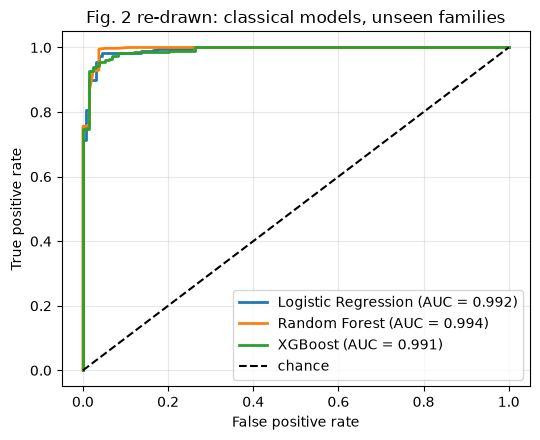

In [9]:
def metrics(y, pred, proba):
    return {"Accuracy": 100 * accuracy_score(y, pred), "Precision": 100 * precision_score(y, pred, zero_division=0),
            "Recall": 100 * recall_score(y, pred, zero_division=0), "F1": 100 * f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, proba) if len(np.unique(proba)) > 1 else 0.5}

# CHOICE: default hyper-parameters, as in the authors' code (the paper mentions cross-validated tuning that the code does not show).
CLASSICAL = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
}
cls_res, cls_proba = {}, {}
for name, mdl in CLASSICAL.items():
    t = time.time(); mdl.fit(Xs_tr, y_tr_all)
    pr = mdl.predict_proba(Xs_te)[:, 1]; cls_proba[name] = pr
    cls_res[name] = {**metrics(y_te, mdl.predict(Xs_te), pr), "time_s": time.time() - t}
cls_tab = pd.DataFrame(cls_res).T
display(cls_tab.round({"Accuracy": 2, "Precision": 2, "Recall": 2, "F1": 2, "AUC": 4, "time_s": 1}))

plt.figure(figsize=(5.5, 4.5))
for name, pr in cls_proba.items():
    fpr, tpr, _ = roc_curve(y_te, pr); plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {cls_res[name]['AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="chance"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Fig. 2 re-drawn: classical models, unseen families"); plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4. The hybrid quantum classifier (Algorithm 1, steps 11-18)

For each qubit count `n`: `ZZFeatureMap` (reps 1) encodes the `n` PCA scores, `RealAmplitudes` (reps 3, `4n` parameters)
transforms the state, COBYLA minimises the `VQC` cost, and the predicted class is the value of the measured parity. The function
below runs one such training and returns the test metrics, the cost history (one value per COBYLA evaluation, from the callback),
predictions and timing. The `encoding` argument is `"paper"` (raw PCA scores as angles) or `"minmax"` (the ablation of section 11).

In [10]:
def stratified_subset(y, n, seed):
    if n is None or n >= len(y): return np.arange(len(y))
    r = np.random.default_rng(seed); idx = []
    for c in (0, 1):
        ic = np.flatnonzero(y == c); k = int(round(n * len(ic) / len(y)))
        idx.append(r.choice(ic, size=k, replace=False))
    return np.sort(np.concatenate(idx))

def build_vqc(n, maxiter, seed, callback=None):
    fm = zz_feature_map(n, reps=FEATURE_MAP_REPS)                    # CHOICE: reps=1 (authors' code)
    an = real_amplitudes(n, reps=ANSATZ_REPS)                         # CHOICE: reps=3 (authors' code)
    smp = ExactBatchedSampler(n, dtype=np.complex64 if n >= 11 else np.complex128)
    x0 = np.random.default_rng(seed).random(an.num_parameters)        # CHOICE: authors' initial point
    vqc = VQC(feature_map=fm, ansatz=an, optimizer=COBYLA(maxiter=maxiter), sampler=smp,
              initial_point=x0, callback=callback)
    use_fast_postprocess(vqc)
    return vqc, fm, an

def run_vqc(n, seed=SEED, encoding="paper", maxiter=None, n_train=N_TRAIN, live=False, label=""):
    maxiter = maxiter or MAXITER[n]
    algorithm_globals.random_seed = seed
    idx = stratified_subset(y_tr_all, n_train, SEED)                   # same subset for every run
    Xa, Xb, ya = Z_tr[n][idx], Z_te[n], y_tr_all[idx]
    if encoding == "minmax":                                           # fitted on the training scores only
        mm = MinMaxScaler((0, np.pi)).fit(Z_tr[n]); Xa = mm.transform(Xa)
        Xb = np.clip(mm.transform(Xb), 0, np.pi)
    hist = []
    def cb(w, val):
        hist.append(float(val))
        if live and LIVE_PLOT and len(hist) % LIVE_EVERY == 0:
            clear_output(wait=True); plt.figure(figsize=(5, 2.6)); plt.plot(hist, "-o", ms=2)
            plt.xlabel("COBYLA evaluation"); plt.ylabel("cost"); plt.title(f"{label} {n} qubits, seed {seed}"); plt.grid(alpha=.3); plt.show()
    vqc, fm, an = build_vqc(n, maxiter, seed, cb)
    t = time.time(); vqc.fit(Xa, ya); t_fit = time.time() - t
    t = time.time(); proba = vqc.neural_network.forward(Xb, vqc.weights)[:, 1]; t_pred = time.time() - t
    pred = (proba > 0.5).astype(int)
    out = {"n": n, "seed": seed, "encoding": encoding, "n_train": len(ya), "maxiter": maxiter, "n_evals": len(hist),
           **metrics(y_te, pred, proba), "time_s": t_fit + t_pred, "hist": hist, "proba": proba, "pred": pred,
           "weights": np.array(vqc.weights), "params": an.num_parameters}
    return out

### 4.1 One tiny circuit, drawn

For orientation: the 4-qubit model of the paper. Left, the `ZZFeatureMap` (data); right, the `RealAmplitudes` ansatz (weights).

feature map ops: {'u': 14, 'cx': 12} | ansatz parameters: 16


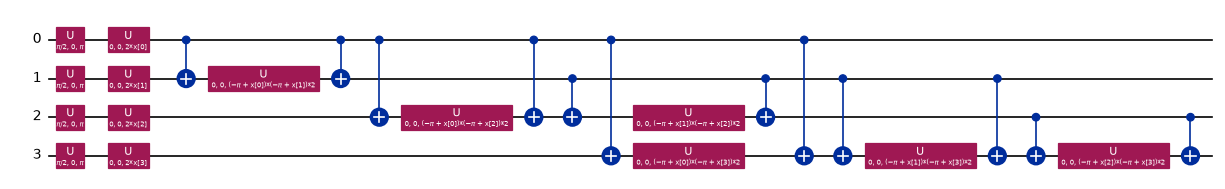

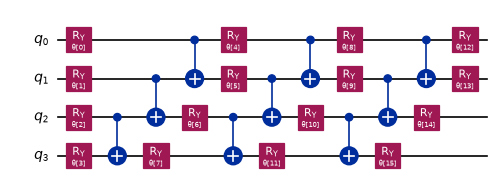

{4: 16, 8: 32, 12: 48} trainable parameters for 4 / 8 / 12 qubits


In [11]:
fm4 = zz_feature_map(4, reps=FEATURE_MAP_REPS); an4 = real_amplitudes(4, reps=ANSATZ_REPS)
print("feature map ops:", dict(fm4.decompose().count_ops()), "| ansatz parameters:", an4.num_parameters)
display(fm4.decompose().draw("mpl", fold=40, scale=0.6))
display(an4.draw("mpl", fold=40, scale=0.6))
print({n: real_amplitudes(n, reps=ANSATZ_REPS).num_parameters for n in N_QUBITS_LIST}, "trainable parameters for 4 / 8 / 12 qubits")

## 5. Main experiment: the paper's single run (seed 42), 4 / 8 / 12 qubits (claims C4-C6)

This is the paper's protocol: one training per qubit count with the seed-42 initial point and the COBYLA budgets of Sec. 4.1.
The live plot shows the cost at every evaluation.

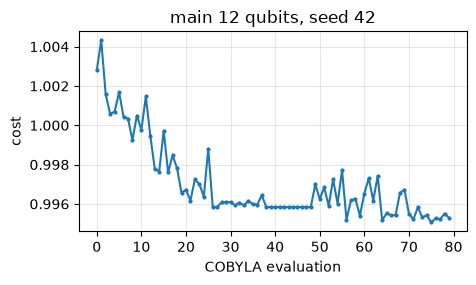

12 qubits | train files 2157 | COBYLA evals 80/80 | acc 52.32 prec 74.82 rec 54.03 F1 62.75 AUC 0.4909 | 1872s


In [12]:
main = {}
for n in N_QUBITS_LIST:
    main[n] = run_vqc(n, seed=SEED, live=True, label="main")
    r = main[n]
    print(f"{n:2d} qubits | train files {r['n_train']} | COBYLA evals {r['n_evals']}/{r['maxiter']} | "
          f"acc {r['Accuracy']:.2f} prec {r['Precision']:.2f} rec {r['Recall']:.2f} F1 {r['F1']:.2f} AUC {r['AUC']:.4f} | {r['time_s']:.0f}s")

Accuracy  Precision  Recall     F1     AUC
qubits source                                              
4      paper        48.65      78.47   42.60  55.22  0.5994
       notebook     56.56      79.63   55.84  65.65  0.6087
8      paper        44.98      74.04   40.00  51.94  0.4624
       notebook     58.88      81.16   58.18  67.78  0.6312
12     paper        51.74      73.36   55.06  62.91  0.5374
       notebook     52.32      74.82   54.03  62.75  0.4909

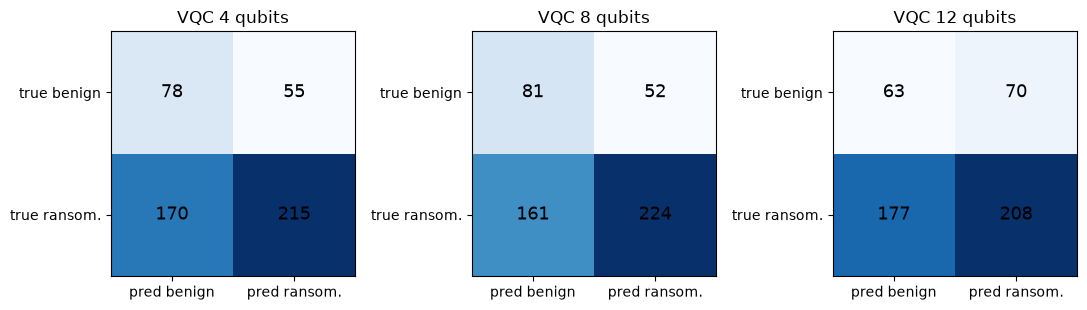

Always-ransomware baseline on this test set: acc 74.3, prec 74.3, rec 100, F1 85.3, AUC 0.5


In [13]:
PAPER_VQC = {4: dict(Accuracy=48.65, Precision=78.47, Recall=42.60, F1=55.22, AUC=0.5994),
             8: dict(Accuracy=44.98, Precision=74.04, Recall=40.00, F1=51.94, AUC=0.4624),
             12: dict(Accuracy=51.74, Precision=73.36, Recall=55.06, F1=62.91, AUC=0.5374)}
rows = []
for n in N_QUBITS_LIST:
    for who, d in (("paper", PAPER_VQC[n]), ("notebook", {k: main[n][k] for k in PAPER_VQC[n]})):
        rows.append({"qubits": n, "source": who, **d})
tab2 = pd.DataFrame(rows).set_index(["qubits", "source"])
display(tab2.round({"Accuracy": 2, "Precision": 2, "Recall": 2, "F1": 2, "AUC": 4}))

fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, n in zip(axs, N_QUBITS_LIST):
    cm = confusion_matrix(y_te, main[n]["pred"], labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.set_title(f"VQC {n} qubits")
    ax.set_xticks([0, 1], ["pred benign", "pred ransom."]); ax.set_yticks([0, 1], ["true benign", "true ransom."])
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", color="k", fontsize=13)
plt.tight_layout(); plt.show()
print("Always-ransomware baseline on this test set: acc %.1f, prec %.1f, rec 100, F1 %.1f, AUC 0.5"
      % (100*y_te.mean(), 100*y_te.mean(), 100*f1_score(y_te, np.ones_like(y_te))))

## 6. Fig. 3 re-drawn: recall against qubit count (claim C8) and the gap to the classical models (claim C7)

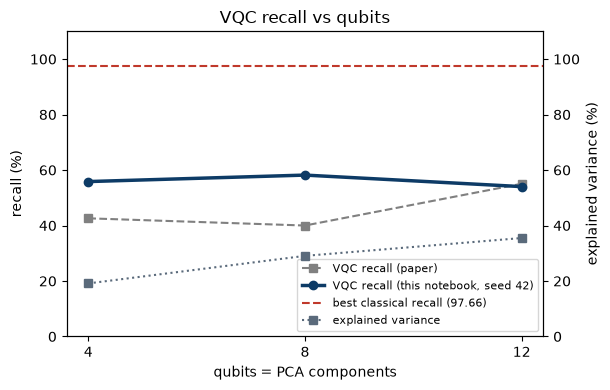

recall 4/8/12 qubits (seed 42): [55.84, 58.18, 54.03] | non-monotonic (4>8<12): False


In [14]:
best_cls_rec = max(v["Recall"] for v in cls_res.values())
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.plot(N_QUBITS_LIST, [PAPER_VQC[n]["Recall"] for n in N_QUBITS_LIST], "s--", color="grey", label="VQC recall (paper)")
ax.plot(N_QUBITS_LIST, [main[n]["Recall"] for n in N_QUBITS_LIST], "o-", lw=2.5, color="#0d3b66", label="VQC recall (this notebook, seed 42)")
ax.axhline(best_cls_rec, color="#c0392b", ls="--", label=f"best classical recall ({best_cls_rec:.2f})")
ax2 = ax.twinx(); ax2.plot(N_QUBITS_LIST, [expl[n] for n in N_QUBITS_LIST], "s:", color="#5a6a7b", label="explained variance")
ax.set_xticks(N_QUBITS_LIST); ax.set_xlabel("qubits = PCA components"); ax.set_ylabel("recall (%)"); ax2.set_ylabel("explained variance (%)")
ax.set_ylim(0, 110); ax2.set_ylim(0, 110); h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8); ax.set_title("VQC recall vs qubits"); plt.tight_layout(); plt.show()
rec = [main[n]["Recall"] for n in N_QUBITS_LIST]
print("recall 4/8/12 qubits (seed 42):", [round(r, 2) for r in rec], "| non-monotonic (4>8<12):", rec[0] > rec[1] < rec[2])

## 7. Training dynamics (claim C9)

The paper reads the cost logs of the three runs: 4 qubits "consistently decreased", 8 qubits "effectively flat", 12 qubits "slight
decrease". We quantify the same thing with the relative drop of the cost, `(mean of first 5 evaluations - mean of last 5) / mean of
first 5`, and the best cost reached relative to the starting cost.

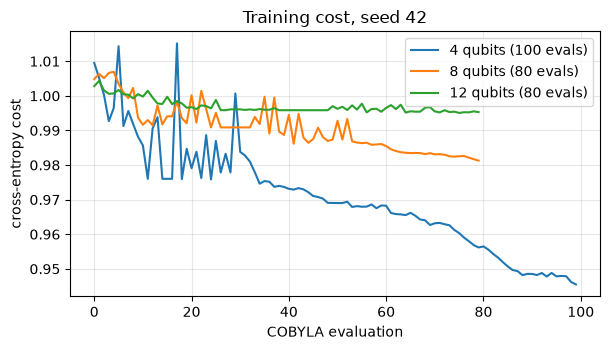

,qubits,first cost,last cost,min cost,drop first5->last5 (%),best vs first (%)
0,4,1.0095,0.9455,0.9455,5.3698,6.3402
1,8,1.0048,0.9813,0.9813,2.3772,2.3461
2,12,1.0028,0.9953,0.9951,0.6705,0.7719


In [15]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
dyn = []
for n in N_QUBITS_LIST:
    h = np.array(main[n]["hist"]); ax.plot(h, label=f"{n} qubits ({len(h)} evals)")
    drop = 100 * (h[:5].mean() - h[-5:].mean()) / h[:5].mean(); best = 100 * (h[0] - h.min()) / h[0]
    dyn.append({"qubits": n, "first cost": h[0], "last cost": h[-1], "min cost": h.min(),
                "drop first5->last5 (%)": drop, "best vs first (%)": best})
ax.set_xlabel("COBYLA evaluation"); ax.set_ylabel("cross-entropy cost"); ax.set_title("Training cost, seed 42"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
dyn = pd.DataFrame(dyn); display(dyn.round(4))

## 8. Is the pattern reproducible? More random initial points (tests the "non-monotonic" claim C8)

The paper reports **one** run per qubit count. COBYLA is deterministic once the initial point is fixed, so the only source of variation
is the initial point (and, with a training subset, the subset). We repeat the 4- and 8-qubit trainings with other initial points
(`EXTRA_SEEDS`) and, if configured, the 12-qubit one; the mean +- standard deviation over seeds then says whether "4q > 8q < 12q" is
a stable trend or a coincidence of one run.

In [16]:
multi = {n: [main[n]] for n in N_QUBITS_LIST}
for n in N_QUBITS_LIST:
    seeds = EXTRA_SEEDS if n != 12 else EXTRA_SEEDS_12Q
    for s in seeds:
        multi[n].append(run_vqc(n, seed=s))
        r = multi[n][-1]; print(f"{n:2d} qubits seed {s}: rec {r['Recall']:.2f} acc {r['Accuracy']:.2f} AUC {r['AUC']:.4f} ({r['time_s']:.0f}s)")
rows = []
for n in N_QUBITS_LIST:
    R = pd.DataFrame([{k: r[k] for k in ("Accuracy", "Precision", "Recall", "F1", "AUC")} for r in multi[n]])
    rows.append({"qubits": n, "runs": len(R), **{f"{k} mean": R[k].mean() for k in R}, **{f"{k} std": R[k].std(ddof=0) for k in ("Recall", "AUC")}})
multi_tab = pd.DataFrame(rows).set_index("qubits"); display(multi_tab.round(3))
if len(multi[4]) > 1:
    r4 = [r["Recall"] for r in multi[4]]; r8 = [r["Recall"] for r in multi[8]]
    print("4q recall per seed:", np.round(r4, 1)); print("8q recall per seed:", np.round(r8, 1))
    print("fraction of seeds with recall(8q) < recall(4q): %.2f" % np.mean(np.array(r8) < np.array(r4)))

 4 qubits seed 43: rec 61.82 acc 61.20 AUC 0.6877 (4s)


 4 qubits seed 44: rec 58.96 acc 59.27 AUC 0.6327 (3s)


 4 qubits seed 45: rec 43.38 acc 48.26 AUC 0.5658 (4s)


 4 qubits seed 46: rec 56.62 acc 60.04 AUC 0.6436 (4s)


 8 qubits seed 43: rec 36.62 acc 38.80 AUC 0.4319 (172s)


 8 qubits seed 44: rec 55.58 acc 58.49 AUC 0.6598 (197s)


 8 qubits seed 45: rec 45.45 acc 45.95 AUC 0.4642 (181s)


 8 qubits seed 46: rec 49.61 acc 52.70 AUC 0.5447 (147s)


,runs,Accuracy mean,Precision mean,Recall mean,F1 mean,AUC mean,Recall std,AUC std
qubits,,,,,,,,
4,5,57.066,80.733,55.325,65.504,0.628,6.326,0.040
8,5,50.965,76.069,49.091,59.580,0.546,7.665,0.089
12,1,52.317,74.820,54.026,62.745,0.491,0.000,0.000


4q recall per seed: [55.8 61.8 59.  43.4 56.6]
8q recall per seed: [58.2 36.6 55.6 45.5 49.6]
fraction of seeds with recall(8q) < recall(4q): 0.60


## 9. Diagnostic 1: is it an information bottleneck? Classical models on the *same* 4 / 8 / 12 PCA inputs (claim C10, part 1)

If the 19-36 % of retained variance were the real limit, then any classifier fed with those same PCA scores should struggle too.
We train Logistic Regression, an RBF SVM and a Random Forest on exactly the inputs the VQC sees.

,qubits (PCs),model,Accuracy,Precision,Recall,F1,AUC
0,4,LR,83.01,87.22,90.39,88.78,0.8232
1,4,SVC rbf,72.20,83.01,78.70,80.80,0.8500
2,4,RF,79.15,96.63,74.55,84.16,0.8739
3,8,LR,76.64,85.11,83.12,84.10,0.8301
4,8,SVC rbf,75.68,88.43,77.40,82.55,0.8836
5,8,RF,78.57,96.60,73.77,83.65,0.8470
6,12,LR,82.24,86.00,90.91,88.38,0.8917
7,12,SVC rbf,83.59,96.01,81.30,88.05,0.9194
8,12,RF,78.76,98.59,72.47,83.53,0.8731


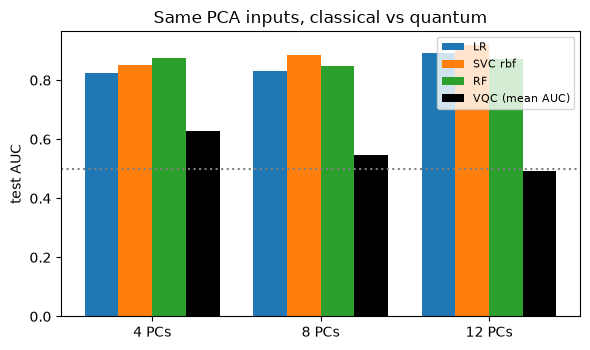

In [17]:
rows = []
for n in N_QUBITS_LIST:
    for name, mdl in (("LR", LogisticRegression(max_iter=1000, random_state=SEED)),
                      ("SVC rbf", SVC(kernel="rbf", probability=True, random_state=SEED)),
                      ("RF", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1))):
        mdl.fit(Z_tr[n], y_tr_all); pr = mdl.predict_proba(Z_te[n])[:, 1]
        rows.append({"qubits (PCs)": n, "model": name, **metrics(y_te, mdl.predict(Z_te[n]), pr)})
pca_cls = pd.DataFrame(rows); display(pca_cls.round({"Accuracy": 2, "Precision": 2, "Recall": 2, "F1": 2, "AUC": 4}))
fig, ax = plt.subplots(figsize=(6, 3.6)); w = 0.2
for k, name in enumerate(["LR", "SVC rbf", "RF"]):
    sub = pca_cls[pca_cls.model == name]; ax.bar(np.arange(3) + k * w, sub["AUC"], w, label=name)
ax.bar(np.arange(3) + 3 * w, [np.mean([r["AUC"] for r in multi[n]]) for n in N_QUBITS_LIST], w, label="VQC (mean AUC)", color="k")
ax.set_xticks(np.arange(3) + 1.5 * w, [f"{n} PCs" for n in N_QUBITS_LIST]); ax.set_ylabel("test AUC"); ax.axhline(0.5, color="grey", ls=":")
ax.set_title("Same PCA inputs, classical vs quantum"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 10. Diagnostic 2: is there a barren plateau? Gradient variance at random parameters (claim C10, part 2)

A barren plateau means the gradient of the cost has exponentially small *variance over random parameters*. We estimate it directly:
for each qubit count we draw random weights `theta ~ U(0, 2 pi)`, compute the exact gradient of the VQC cross-entropy
(parameter-shift rule on the RY rotations of the ansatz, chain rule through the cross-entropy) on a small batch of training files, for
three weights (first, middle, last), and report the variance over the draws. COBYLA does not use gradients, but this variance measures
how much signal the landscape offers at initialisation.

,qubits,n_params,mean cost at random theta,var grad (avg of 3 weights),mean |grad|
0,4,16,0.720186,0.000382,0.012926
1,8,32,0.694358,0.000029,0.003268
2,12,48,0.693088,0.000002,0.000746


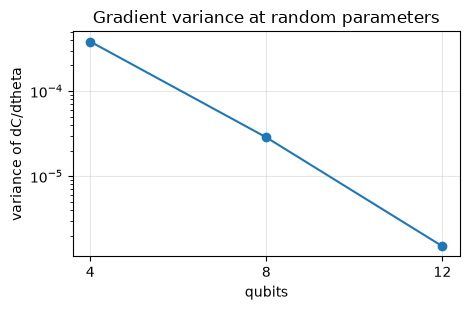

In [18]:
def ce_and_grad(q, W, Xb, yb, idx_params):
    """Cross-entropy and its exact parameter-shift gradient for the weights in idx_params."""
    P = lambda w: np.clip(q.forward(Xb, w), 1e-12, 1)
    Y = np.eye(2)[yb]
    p0 = P(W); ce = -np.mean(np.sum(Y * np.log(p0), axis=1))
    g = []
    for k in idx_params:
        wp, wm = W.copy(), W.copy(); wp[k] += np.pi / 2; wm[k] -= np.pi / 2
        dp = 0.5 * (P(wp) - P(wm))                         # d p_c / d theta_k  (exact for RY rotations)
        g.append(-np.mean(np.sum(Y * dp / p0, axis=1)))
    return ce, np.array(g)

gr = np.random.default_rng(SEED); gres = []
for n in N_QUBITS_LIST:
    idx = stratified_subset(y_tr_all, GRAD_SAMPLES, SEED); Xb, yb = Z_tr[n][idx], y_tr_all[idx]
    npar = real_amplitudes(n, reps=ANSATZ_REPS).num_parameters; ip = [0, npar // 2, npar - 1]
    G, C = [], []
    qnn = build_vqc(n, 1, SEED)[0].neural_network
    for _ in range(GRAD_DRAWS):
        W = gr.uniform(0, 2 * np.pi, npar); ce, g = ce_and_grad(qnn, W, Xb, yb, ip); G.append(g); C.append(ce)
    G = np.array(G)
    gres.append({"qubits": n, "n_params": npar, "mean cost at random theta": np.mean(C), "var grad (avg of 3 weights)": G.var(axis=0).mean(),
                 "mean |grad|": np.abs(G).mean()})
gres = pd.DataFrame(gres); display(gres)
plt.figure(figsize=(4.8, 3.2)); plt.semilogy(gres["qubits"], gres["var grad (avg of 3 weights)"], "o-"); plt.xticks(N_QUBITS_LIST)
plt.xlabel("qubits"); plt.ylabel("variance of dC/dtheta"); plt.title("Gradient variance at random parameters"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 11. Diagnostic 3: the same VQC with the angles rescaled to [0, pi]

The paper feeds raw PCA scores (range +-60) to `ZZFeatureMap`. This ablation applies the library's usual convention
(`MinMaxScaler((0, pi))` fitted on the training scores, test values clipped to [0, pi]) and changes nothing else. If the encoding is part of
the problem, accuracy and AUC should move away from chance.

 4 qubits (minmax) | acc 60.81 prec 78.62 rec 64.94 F1 71.12 AUC 0.6557 | 4s


 8 qubits (minmax) | acc 50.58 prec 75.90 rec 49.09 F1 59.62 AUC 0.5775 | 189s


,qubits,encoding,Accuracy,Precision,Recall,F1,AUC
2,4,"minmax [0, pi]",60.81,78.62,64.94,71.12,0.6557
0,4,raw PCA (paper),56.56,79.63,55.84,65.65,0.6087
3,8,"minmax [0, pi]",50.58,75.90,49.09,59.62,0.5775
1,8,raw PCA (paper),58.88,81.16,58.18,67.78,0.6312


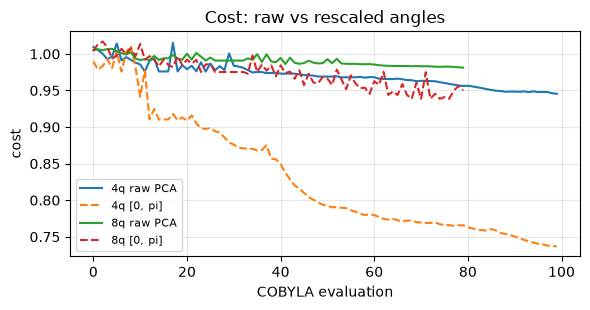

In [19]:
abl = {}
for n in ABLATION_QUBITS:
    abl[n] = run_vqc(n, seed=SEED, encoding="minmax")
    r = abl[n]; print(f"{n:2d} qubits (minmax) | acc {r['Accuracy']:.2f} prec {r['Precision']:.2f} rec {r['Recall']:.2f} F1 {r['F1']:.2f} AUC {r['AUC']:.4f} | {r['time_s']:.0f}s")
ab = pd.DataFrame([{"qubits": n, "encoding": "raw PCA (paper)", **{k: main[n][k] for k in ("Accuracy", "Precision", "Recall", "F1", "AUC")}} for n in ABLATION_QUBITS] +
                  [{"qubits": n, "encoding": "minmax [0, pi]", **{k: abl[n][k] for k in ("Accuracy", "Precision", "Recall", "F1", "AUC")}} for n in ABLATION_QUBITS]).sort_values(["qubits", "encoding"])
display(ab.round({"Accuracy": 2, "Precision": 2, "Recall": 2, "F1": 2, "AUC": 4}))
plt.figure(figsize=(6, 3.2))
for n in ABLATION_QUBITS:
    plt.plot(main[n]["hist"], label=f"{n}q raw PCA"); plt.plot(abl[n]["hist"], "--", label=f"{n}q [0, pi]")
plt.xlabel("COBYLA evaluation"); plt.ylabel("cost"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.title("Cost: raw vs rescaled angles"); plt.tight_layout(); plt.show()

## 12. Side-by-side comparison with the paper and a verdict per claim

Rule (from the factory brief): a number is **reproduced** if it lies within 2 percentage points (0.02 for AUC) of the paper's value;
otherwise **not reached** (ours is lower) or **exceeded** (ours is higher), with the gap shown. Qualitative claims get an explicit
yes / no with the evidence.

In [20]:
def verdict(paper, ours, tol):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached"), d

rows = []
# C1, C2
rows.append(("C1 split sizes / families / D", "2157, 518, 25/15, 1567",
             f"{len(train_df)}, {len(test_df)}, {len(tr_fam)}/{len(te_fam)}, {len(FEATURES)}", "reproduced"))
for n in N_QUBITS_LIST:
    v, d = verdict(PAPER_VAR[n], expl[n], 0.1)
    rows.append((f"C2 explained variance {n} PCs (%)", PAPER_VAR[n], round(expl[n], 2), f"{v} ({d:+.2f})"))
# C3
PAPER_CLS = {"Logistic Regression": dict(Accuracy=97.10, Precision=98.43, Recall=97.66, F1=98.04, AUC=0.9920),
             "Random Forest": dict(Accuracy=95.95, Precision=98.66, Recall=95.84, F1=97.23, AUC=0.9940),
             "XGBoost": dict(Accuracy=95.75, Precision=99.19, Recall=95.06, F1=97.08, AUC=0.9940)}
for name, pv in PAPER_CLS.items():
    for k, p in pv.items():
        o = cls_res[name][k]; v, d = verdict(p, o, 0.02 if k == "AUC" else 2.0)
        rows.append((f"C3 {name} {k}", p, round(o, 4 if k == "AUC" else 2), f"{v} ({d:+.4f})" if k == "AUC" else f"{v} ({d:+.2f})"))
# C4-C6
for cid, n in (("C4", 4), ("C5", 8), ("C6", 12)):
    for k, p in PAPER_VQC[n].items():
        o = main[n][k]; v, d = verdict(p, o, 0.02 if k == "AUC" else 2.0)
        rows.append((f"{cid} VQC {n}q {k}", p, round(o, 4 if k == "AUC" else 2), f"{v} ({d:+.4f})" if k == "AUC" else f"{v} ({d:+.2f})"))
# C7
best_vqc = max(main[n]["Recall"] for n in N_QUBITS_LIST); gap = best_cls_rec - best_vqc
rows.append(("C7 best VQC recall << best classical recall (gap > 42 pts)", "55.06 vs 97.66 (gap 42.6)", f"{best_vqc:.2f} vs {best_cls_rec:.2f} (gap {gap:.1f})",
             "reproduced" if gap > 40 else "not reached"))
acc_vqc = [main[n]["Accuracy"] for n in N_QUBITS_LIST]
rows.append(("C7b every VQC accuracy < every classical accuracy", "yes (max 51.74 < min 95.75)", f"max VQC {max(acc_vqc):.2f} vs min classical {min(v['Accuracy'] for v in cls_res.values()):.2f}",
             "reproduced" if max(acc_vqc) < min(v["Accuracy"] for v in cls_res.values()) else "not reached"))
# C8
rec = [main[n]["Recall"] for n in N_QUBITS_LIST]; nm = rec[0] > rec[1] < rec[2]
rows.append(("C8 non-monotonic recall 4q > 8q < 12q (seed 42)", "42.60 > 40.00 < 55.06", " / ".join(f"{r:.2f}" for r in rec), "reproduced" if nm else "not reached"))
if len(multi[4]) > 1:
    a = np.array([r["Recall"] for r in multi[4]]); b = np.array([r["Recall"] for r in multi[8]])
    rows.append(("C8b same ordering 8q < 4q across initial points", "not tested in paper", f"{np.mean(b < a):.0%} of {len(a)} seeds", "cannot be checked against paper"))
# C9
def shape_of(h):
    h = np.array(h); drop = (h[:5].mean() - h[-5:].mean()) / h[:5].mean(); return "decreasing" if drop > 0.10 else ("flat" if drop < 0.03 else "slight decrease"), 100 * drop
claims9 = {4: "decreasing", 8: "flat", 12: "slight decrease"}
for n in N_QUBITS_LIST:
    sh, dr = shape_of(main[n]["hist"])
    rows.append((f"C9 training cost shape, {n}q", claims9[n], f"{sh} (drop {dr:.1f} %)", "reproduced" if sh == claims9[n] else "not reached"))
drops = {n: (np.mean(main[n]["hist"][:5]) - np.mean(main[n]["hist"][-5:])) / np.mean(main[n]["hist"][:5]) for n in N_QUBITS_LIST}
order_ours = sorted(N_QUBITS_LIST, key=lambda n: -drops[n])
rows.append(("C9d ordering of cost drop (largest first): 4q, 12q, 8q", "4q > 12q > 8q", " > ".join(f"{n}q" for n in order_ours), "reproduced" if order_ours == [4, 12, 8] else "not reached"))
# C10
bn = pca_cls.groupby("qubits (PCs)")["AUC"].max()
rows.append(("C10a information bottleneck: classical models on 4/8/12 PCs also fail", "implied (VQC ceiling)", "best classical AUC on PCs: " + ", ".join(f"{n}:{bn[n]:.3f}" for n in N_QUBITS_LIST),
             "not supported" if bn.min() > 0.8 else "supported"))
gv = gres["var grad (avg of 3 weights)"].values
rows.append(("C10b barren plateau: gradient variance falls with qubits", "8q worst (implied)", "var: " + ", ".join(f"{n}q {v:.1e}" for n, v in zip(N_QUBITS_LIST, gv)),
             "supported" if gv[0] > gv[1] > gv[2] else "not clear"))
final = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90, "display.width", 220)
display(final)
print(final["verdict"].str.split(" (", regex=False).str[0].value_counts().to_string())

,claim,paper,this notebook,verdict
0,C1 split sizes / families / D,"2157, 518, 25/15, 1567","2157, 518, 25/15, 1567",reproduced
1,C2 explained variance 4 PCs (%),19.14,19.14,reproduced (-0.00)
2,C2 explained variance 8 PCs (%),29.07,29.07,reproduced (-0.00)
3,C2 explained variance 12 PCs (%),35.5,35.5,reproduced (-0.00)
4,C3 Logistic Regression Accuracy,97.1,97.1,reproduced (+0.00)
5,C3 Logistic Regression Precision,98.43,98.43,reproduced (-0.00)
6,C3 Logistic Regression Recall,97.66,97.66,reproduced (+0.00)
7,C3 Logistic Regression F1,98.04,98.04,reproduced (+0.00)
8,C3 Logistic Regression AUC,0.992,0.9919,reproduced (-0.0001)
9,C3 Random Forest Accuracy,95.95,95.95,reproduced (-0.00)


verdict
reproduced                         27
exceeded                            8
not reached                         6
cannot be checked against paper     1
not supported                       1
supported                           1


## 13. Reading the paper critically

*The results we can and cannot confirm are in the table above; the points below say what they mean.*

1. **The classical side is solid and reproducible.** Logistic Regression, Random Forest and XGBoost on the 1,567 features reach 95-97 %
   accuracy on families never seen in training, essentially to the digit of Table 2 (XGBoost differs slightly across library versions).
   The family hold-out is real (we verified that no ransomware family is shared). That is the paper's most reliable finding, and it
   mostly says that static PE-header features separate ransomware from benign software very well on this dataset.
2. **The VQC numbers are close to chance, and the test set hides it.** 74 % of the test files are ransomware, so predicting
   "ransomware" for everything gives 74 % accuracy and 100 % recall. The paper's VQCs have *lower* accuracy than that (45-52 %) and AUCs
   of 0.46-0.60, i.e. they are no better than coin flips. The "recall of 55 % at 12 qubits" is therefore not a partial success:
   an AUC of 0.54 means the model has almost no ranking power.
3. **"Non-monotonic" is the wrong word for noise around chance.** When every configuration performs at chance level, differences
   such as 42.6 % versus 40.0 % recall are within what different random initial points produce. Section 8 measures this spread: with
   several initial points the ordering of 4 and 8 qubits is not stable, so a single run per setting cannot establish a trend, let alone
   a mechanism. A statement like "performance degrades from 4 to 8 qubits" needs repeated runs with confidence intervals.
4. **The information-bottleneck explanation is not supported by the paper's own setting.** Section 9 feeds exactly the same 4 / 8 / 12
   PCA scores to classical models. If they do much better than the VQC, the PCA compression is not what limits the VQC. (The variance
   percentage is also a poor proxy: ransomware may differ from benign files in low-variance directions, and a supervised projection
   keeps what matters.) Read the numbers in sections 9 and 12 rather than the paper's argument.
5. **The barren-plateau explanation is not tested by the paper either.** Barren plateaus are statements about gradient variance over
   random parameters, usually in deep, wide, randomly initialised circuits; COBYLA is gradient-free; and 8 qubits with 32 parameters
   and depth 3 is far from the regime where exponential concentration bites. The paper only looks at three cost curves. Section 10
   computes the quantity that defines a barren plateau; compare it with the paper's story. A much more plausible culprit is the encoding:
   raw PCA scores of magnitude up to 60 are used as rotation angles, so the feature map wraps around the circle dozens of times, which makes the
   kernel almost random (and the cost landscape rugged). Section 11 tests the effect of rescaling.
6. **Training budgets are tiny.** 80-100 COBYLA evaluations for 32-48 parameters (the 12-qubit run uses 48) is about two evaluations per
   parameter; COBYLA needs `n+1` evaluations just to build its first simplex. "Stagnation" after so few steps is expected and does
   not show that the model is untrainable.
7. **Description versus code.** The text says "MSE", "Z_0 observable" and "AerSampler"; the code runs cross-entropy (the Qiskit `VQC` default),
   a parity read-out (equal to qubit 0) and the exact reference sampler. The JSON for 8 qubits says 100 iterations, the text 80.
   The text also says baseline hyper-parameters were tuned by cross-validation; the code uses defaults. These are small, but they show
   why a reproduction should start from the code.
8. **No quantum advantage claim is made, and none could be.** The paper is an honest negative result for a particular, weak configuration
   (unscaled angles, shallow budget, one seed). It should not be read as evidence that QML cannot detect ransomware, nor as evidence that
   the barren-plateau mechanism operates here.

## 14. Exercises

1. **Seeds.** Add more entries to `EXTRA_SEEDS` and plot recall against qubit count with error bars. How often is 4q > 8q? How large is the
   spread compared with the 12.5-point gap the paper discusses between 4q and 12q?
2. **Budget.** Raise `MAXITER` to 300 for 4 and 8 qubits (cheap) and watch the cost. Does the 8-qubit curve stay flat? Does test AUC move?
3. **Feature map.** Replace `zz_feature_map` by `z_feature_map` (no entanglement) or `pauli_feature_map(paulis=["Z"])` and compare with the ZZ map,
   with and without the [0, pi] rescaling. Is the entangling feature map helping at all on these inputs?
4. **Supervised compression.** Replace PCA by `SelectKBest(f_classif, k=n)` (or LDA with one component) fitted on the training split, keep everything
   else, and re-run 4 / 8 / 12 qubits. If the paper's "information bottleneck" is variance-driven, a label-aware projection should change the picture.
5. **Family-wise evaluation.** Group the test files by `family` (use `test_df["family"]`) and compute the recall of the best classical model and of
   the VQC per held-out family. Are some families systematically missed? Which PE features distinguish them (hint: logistic regression coefficients)?

In [21]:
# Final summary block: runtimes and what was run
print(f"FAST_MODE = {FAST_MODE} | training files used by the VQC: {N_TRAIN or len(y_tr_all)} | COBYLA budgets: {MAXITER}")
print("VQC wall-clock (s) per qubit count, seed 42:", {n: round(main[n]["time_s"]) for n in N_QUBITS_LIST})
print(f"Total notebook time so far: {(time.time() - T0) / 60:.1f} min")

FAST_MODE = False | training files used by the VQC: 2157 | COBYLA budgets: {4: 100, 8: 80, 12: 80}
VQC wall-clock (s) per qubit count, seed 42: {4: 6, 8: 133, 12: 1872}
Total notebook time so far: 52.2 min
